# 2026-09-15_14-22-37  (experiment 1)  -  freely moving, mouse 4103

Each stage reads only what the previous stage wrote into the analysis folder, and
writes exactly what the next stage reads. Raw data is never modified.

| stage | function | writes |
|---|---|---|
| 0 | `run_layout` | `metadata/channel_layout.*` (what was actually recorded) |
| 1 | `run_sync` | `metadata/timebase.json`, `ttls/TTL_Pin_*.npy` |
| 2 | `run_frames` | `camera_alignment/<view>_frame_times.npy`, `metadata/frame_alignment.json` |
| 3 | `run_units` | `units/units.csv` (label, best channel, depth, DV, region), `units/spike_times.npy` |
| 4 | `run_dlc` | `dlc_alignment/<view>_dlc.npz` (all bodyparts on the canonical clock) |
| 5 | `detect_reaches` | `peak_detection/reaches.npz`, `bouts.npz`, `reaches_meta.json` |
| 6 | `run_reach_peth` | `peth/reach_peth_<subset>.npz/.json/_units.csv`, figures in `qc/` |

Canonical time = seconds since the start of the Neuropixels stream.

In [1]:
# --- setup: find the repo so `import fmpipe` works on any machine -------------
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "fmpipe").is_dir())
sys.path.insert(0, str(REPO))

import numpy as np
import matplotlib.pyplot as plt
from fmpipe import (SessionConfig, run_layout, run_sync, run_frames, run_units, plot_probe_units,
                    run_dlc, load_dlc, detect_reaches, plot_reach_zone,
                    run_reach_peth, plot_reach_peth, plot_peth_depth, plot_stacked_regions, compare_peth,
                    plot_probe_modulation,
                    load_ttl, load_frame_times, read_json)

In [2]:
# --- CONFIG: the only cell you edit ------------------------------------------
cfg = SessionConfig(
    data_root = r"K:/",      # folder that holds the session folders (any drive letter)
    session   = "2026-09-15_14-22-37",
    experiment = 1,                  # Open Ephys experiment number
    video_dir = r"S:\MP4_BACKUP",               # counters CSVs / MP4s
    cameras   = {"paw_angled": dict(pin=0, trigger_hz=200.0),
                 "bottom": dict(pin=1, trigger_hz=120.19)},
    segment   = "longest",                      # or a video number, e.g. 3
    # kilosort4 copies can live on several drives with different curation; the copy with the
    # newest curation is used (missing roots are skipped, so this is safe on any machine)
    ks_search_roots = (r"C:\Users\Shermanlab\Documents\Open Ephys", "Z:/"),
    dlc_h5    = {"paw_angled": r"C:\Users\Shermanlab\Desktop\4103-Kevin-2026-09-22\videos\15092026-1_paw_angledDLC_Resnet50_4103Sep22shuffle2_snapshot_best-100.h5"},                          # view -> DLC .h5 (leave {} until DLC is done)
    dlc_max_tail_missing = {},              # only if acquisition lost the last frames (disk full)
    # Reach zone (pixels, primary camera): a reach = paw_center/digit2 with x > x_min AND y > y_min.
    # The camera moves between days. This was PROPOSED automatically from where the paw ends its
    # reaches after pellet presentation: look at the plot below and edit if it looks wrong.
    reach_zone = {"x_min": 311, "y_min": 328},
)
cfg.init_analysis()
cfg.save()
print("analysis folder:", cfg.analysis_dir)

analysis folder: K:\2026-09-15_14-22-37\Record Node 101\2026-09-15_14-22-37_experiment1_recording1_analysis


Layout (settings.xml): bank runs [(0, 151, 1), (152, 383, 0)], y 1520-5340 um
t0 = NP start = 106.649600 s (OE clock); duration 2557.8 s; NI spans +0.010 -> 2557.8 s
Sync: 2558 pulses paired (NI 2558, NP 2558); slope-1=-7.51e-10, offset=-0.4 us, resid std=19.1 us
  pin 0 paw_cam_trigger         509465 rising edges
  pin 1 second_cam_trigger      306181 rising edges
  pin 2 opto_led                     4 rising edges
  pin 3 sync_1hz                  2558 rising edges
  pin 4 back_beam                   48 rising edges
  pin 5 third_cam_trigger            0 rising edges
  pin 6 pellet_beam                  6 rising edges
  pin 7 unused                       0 rising edges



[paw_angled] NI pin 0: 509465 pulses in 1 train(s); 1 counters CSV(s) on 15092026
   train 0: n=  509465       6.18->  2551.94 s   200.0 Hz  TRIGGERED
   train 0 <-> video 1 (509464 rows), trailing pulses 1
   USING video 1: 509464 saved frames of 509464 (0 dropped), 6.18->2551.94 s, interval 4.9969+-0.0090 ms, gaps>15 ms: 0

[bottom] NI pin 1: 306181 pulses in 1 train(s); 1 counters CSV(s) on 15092026
   train 0: n=  306181       6.18->  2552.03 s   120.5 Hz  TRIGGERED
   train 0 <-> video 1 (306169 rows), trailing pulses 12


   USING video 1: 306169 saved frames of 306169 (0 dropped), 6.18->2551.93 s, interval 8.3149+-0.0166 ms, gaps>25 ms: 0
Kilosort/Phy copies (newest curation first):
   K:/                                      curated 2026-09-24 12:22  <-- USED
   C:\Users\Shermanlab\Documents\Open Ephys curated 2026-09-24 08:36
   Z:/                                      curated 2026-09-24 08:36


Best channel agrees with Phy cluster_info 'ch' for 100.0% of clusters
  NOTE only 137 eligible noise units for a control of 210 good units


Labels used from cluster_info.tsv: good=210, noise=177
210 good units in analysis (0 excluded by config)
region  CFA  THAL  VAL  WM
n        97    47   40  26


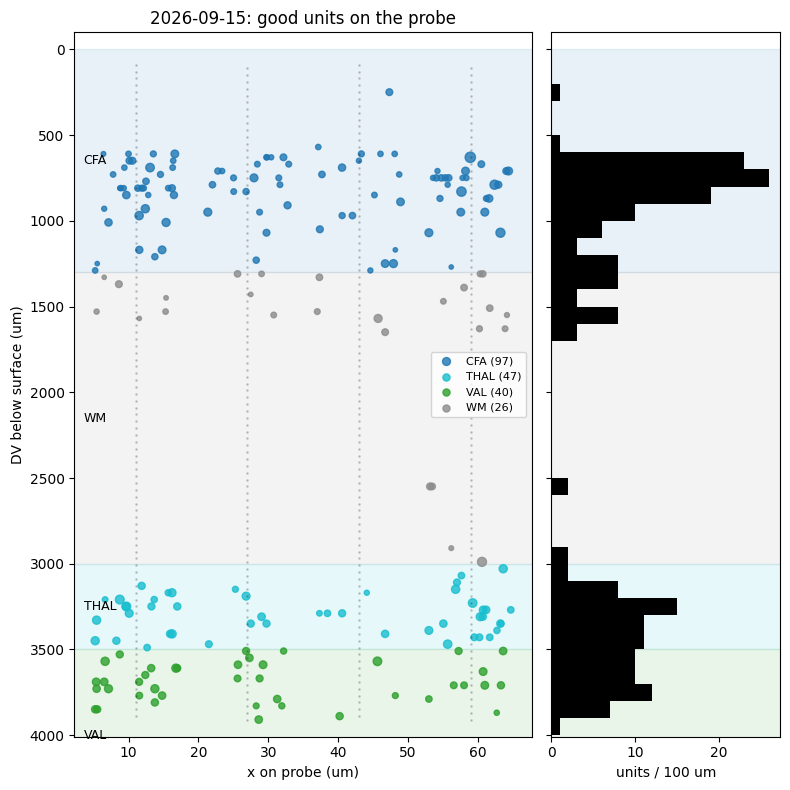

[paw_angled] DLC shuffle2_snapshot_best-100: 509464 rows <-> frames 6.18->2551.94 s
   paw_center  median likelihood 0.383   >=0.5: 41.7%   >=0.9: 14.0%
   digit2      median likelihood 0.335   >=0.5: 37.6%   >=0.9: 10.7%
   nose        median likelihood 0.266   >=0.5: 22.4%   >=0.9: 6.7%
Zone x>311, y>328: 228 reaches in 73 bouts (0 beam-tagged)
  back-beam trials with a bout: 29/48; bout-onset rate inside trial windows 0.67 vs random windows 0.07  (enrichment 9.6x)


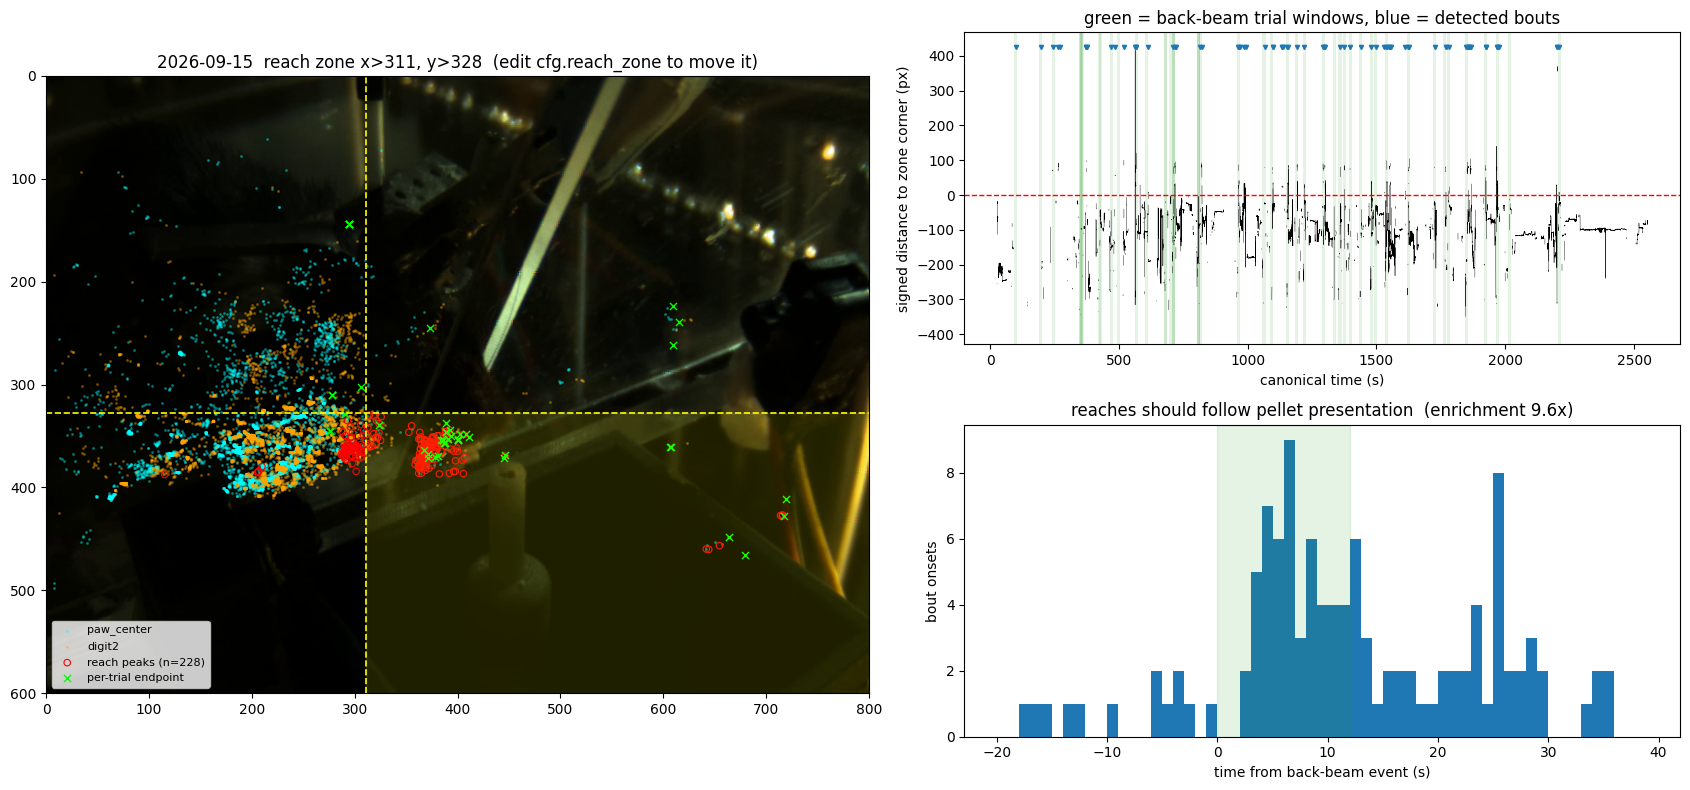

73 events ('all'; window -2.0..+3.0 s, response (-0.5, 2.0)), 200 eligible units ({'CFA': 92, 'THAL': 47, 'VAL': 40, 'WM': 21})


Calibrated Z = 2.75 (shuffled FPR 6.7%);  modulated 119/200
  CFA:  53/92  modulated  (33 excited, 20 suppressed)
   WM:  11/21  modulated  (8 excited, 3 suppressed)
  THAL:  29/47  modulated  (22 excited, 7 suppressed)
  VAL:  26/40  modulated  (17 excited, 9 suppressed)
  THALAMUS:  55/87  modulated  (39 excited, 16 suppressed)


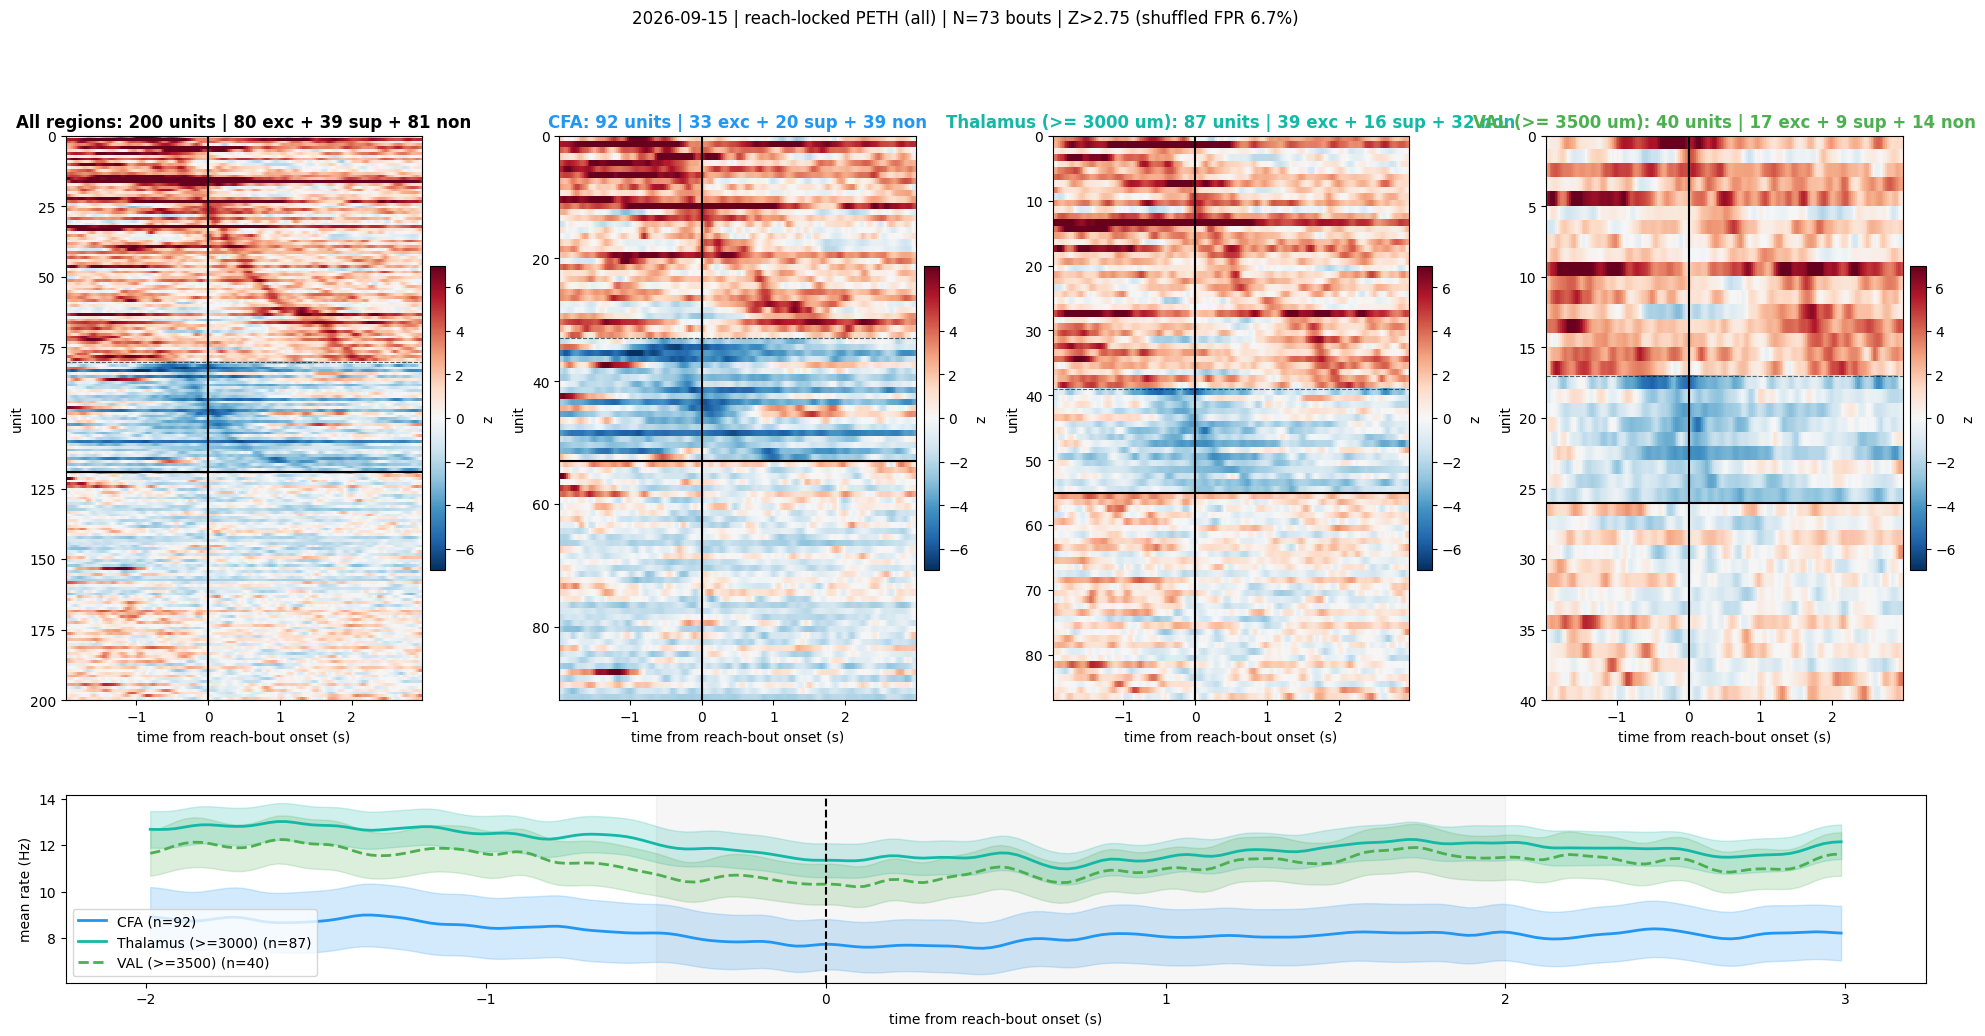

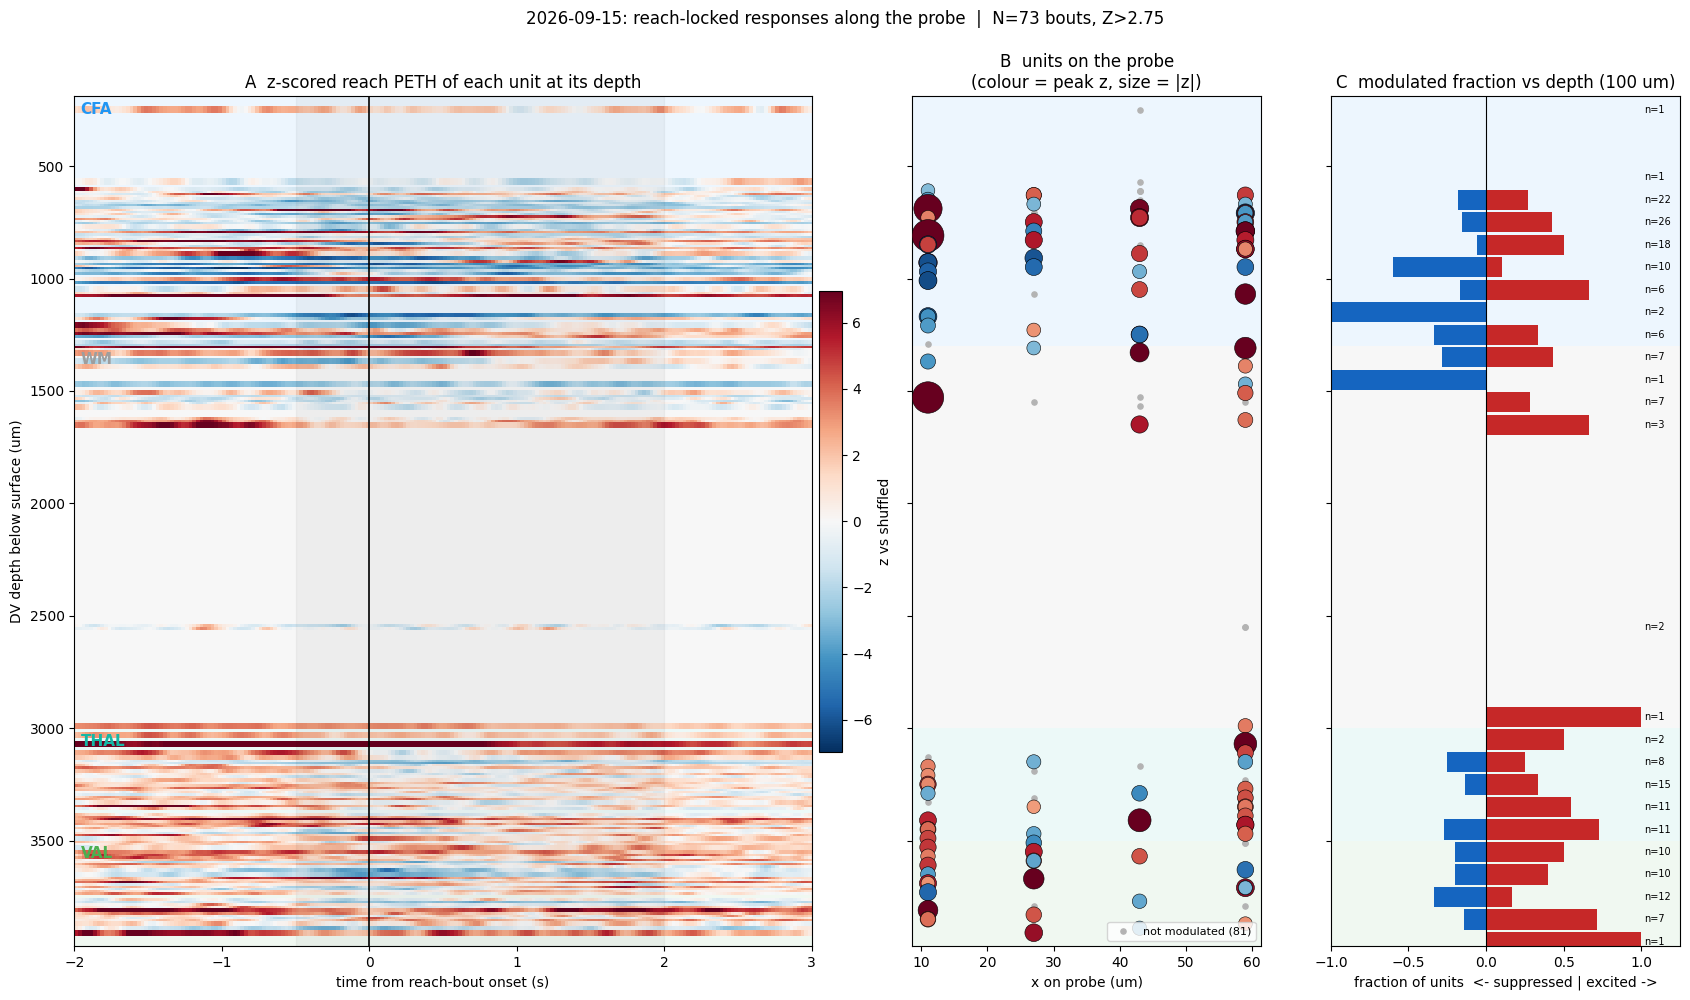

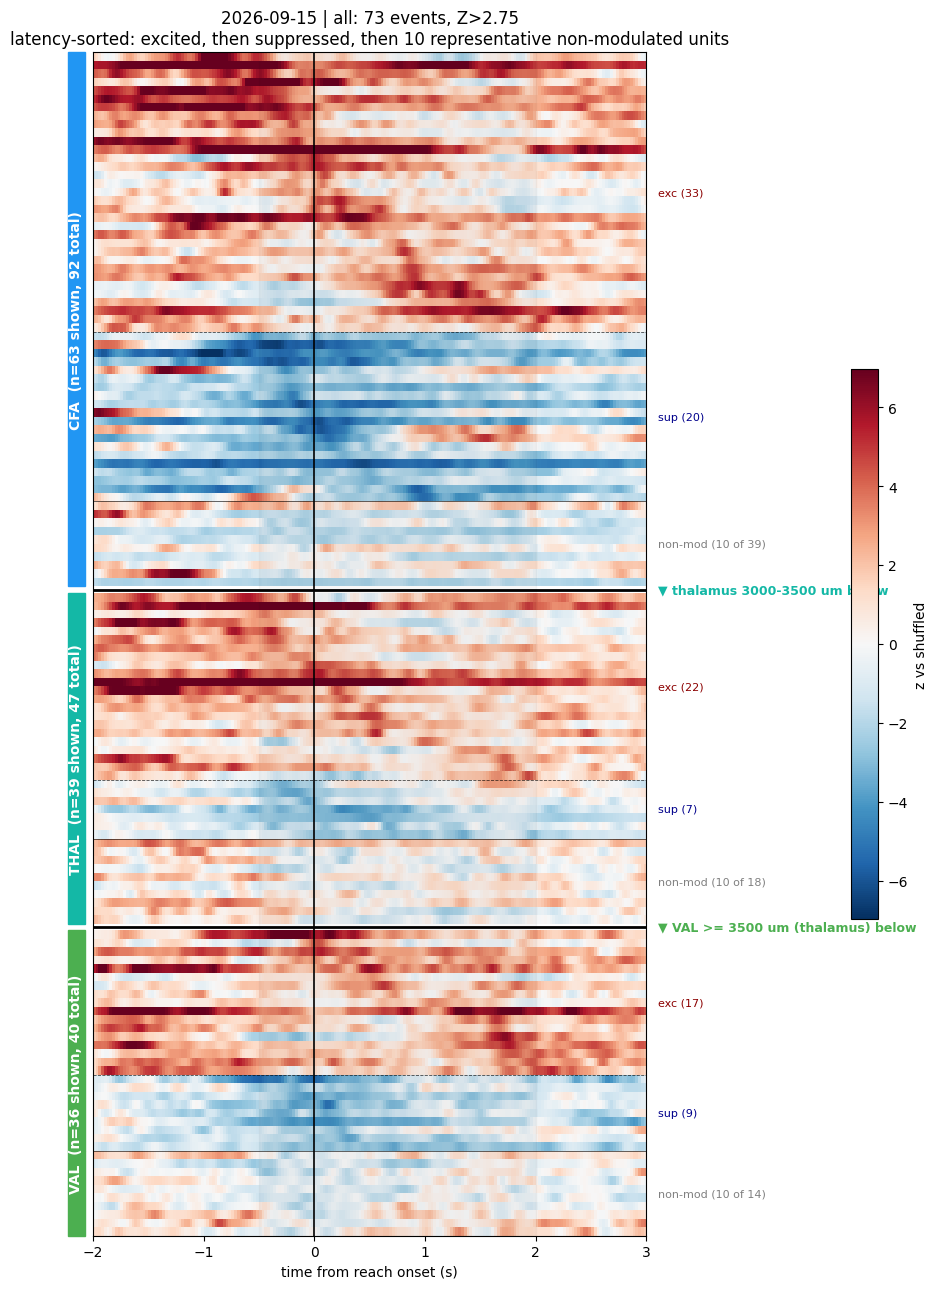

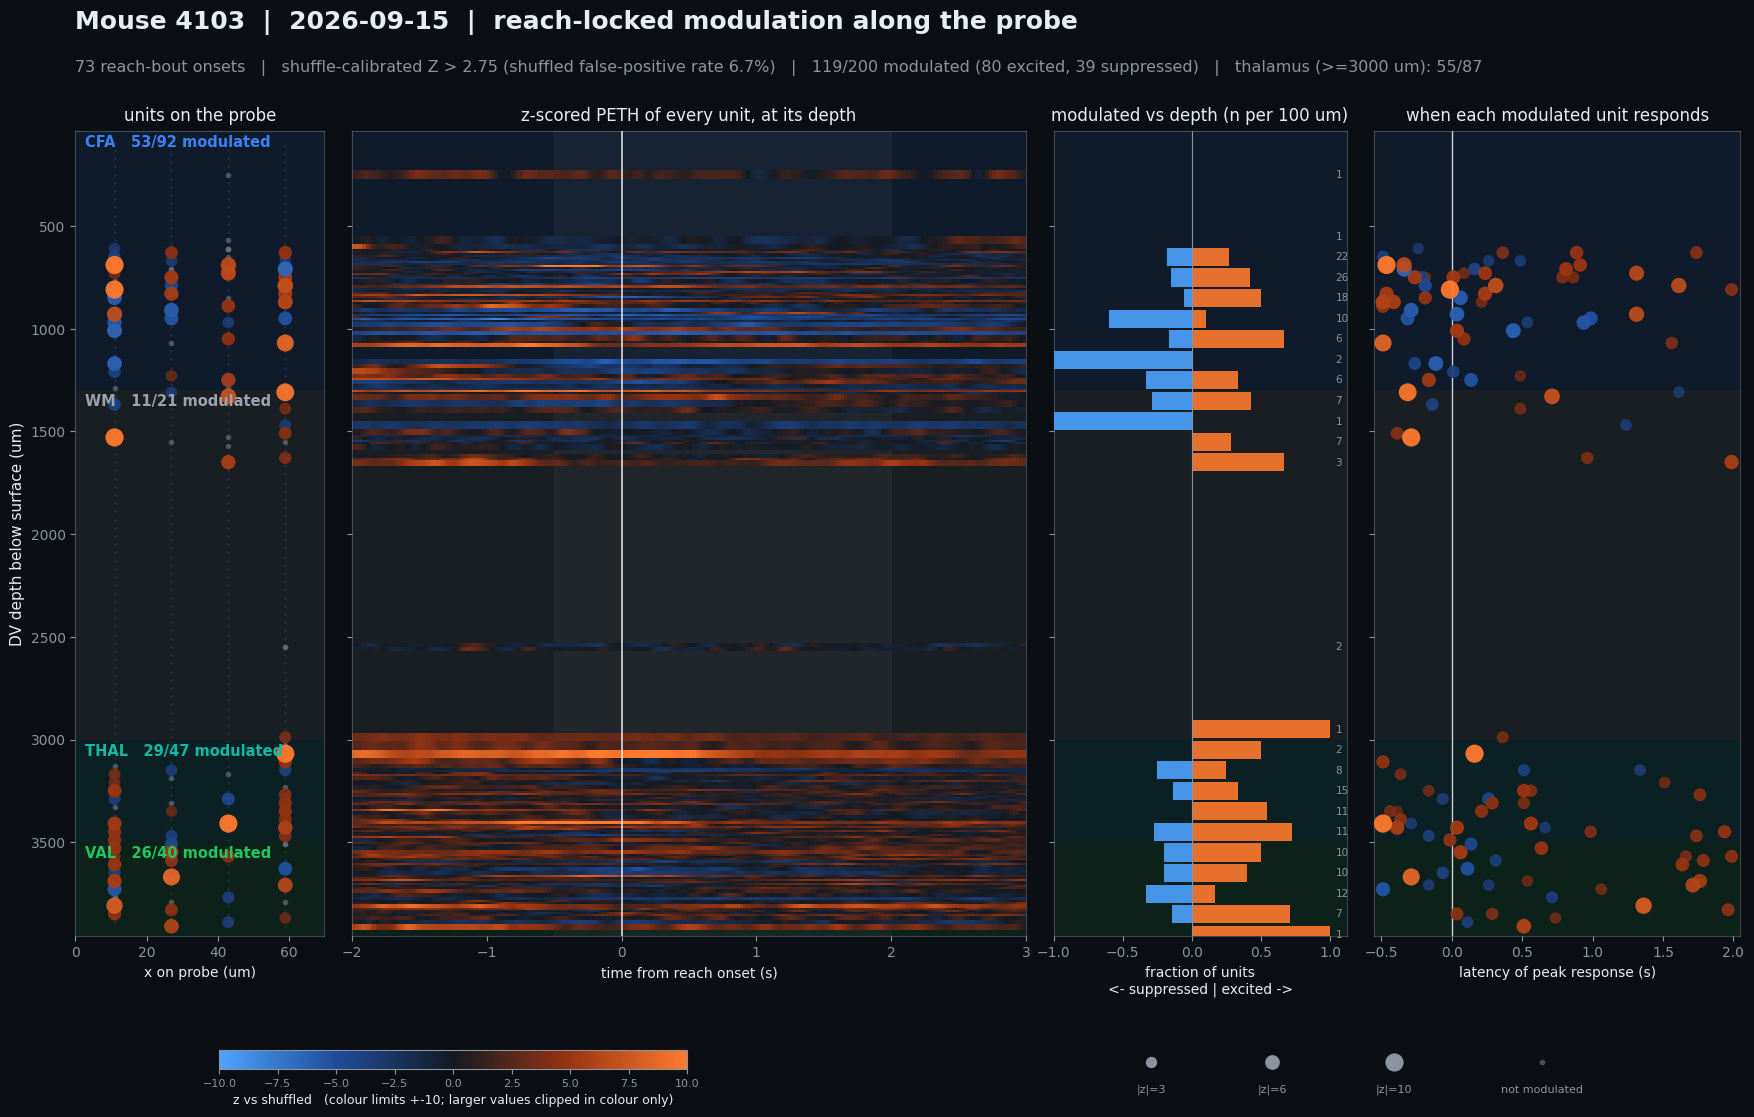

228 events ('all_reaches', in 73 bouts, bout-preserving null; window -1.5..+1.5 s, response (-1.0, 1.0)), 200 eligible units ({'CFA': 92, 'THAL': 47, 'VAL': 40, 'WM': 21})


Calibrated Z = 2.50 (shuffled FPR 7.6%);  modulated 134/200
  CFA:  62/92  modulated  (33 excited, 29 suppressed)
   WM:  10/21  modulated  (6 excited, 4 suppressed)
  THAL:  32/47  modulated  (24 excited, 8 suppressed)
  VAL:  30/40  modulated  (19 excited, 11 suppressed)
  THALAMUS:  62/87  modulated  (43 excited, 19 suppressed)


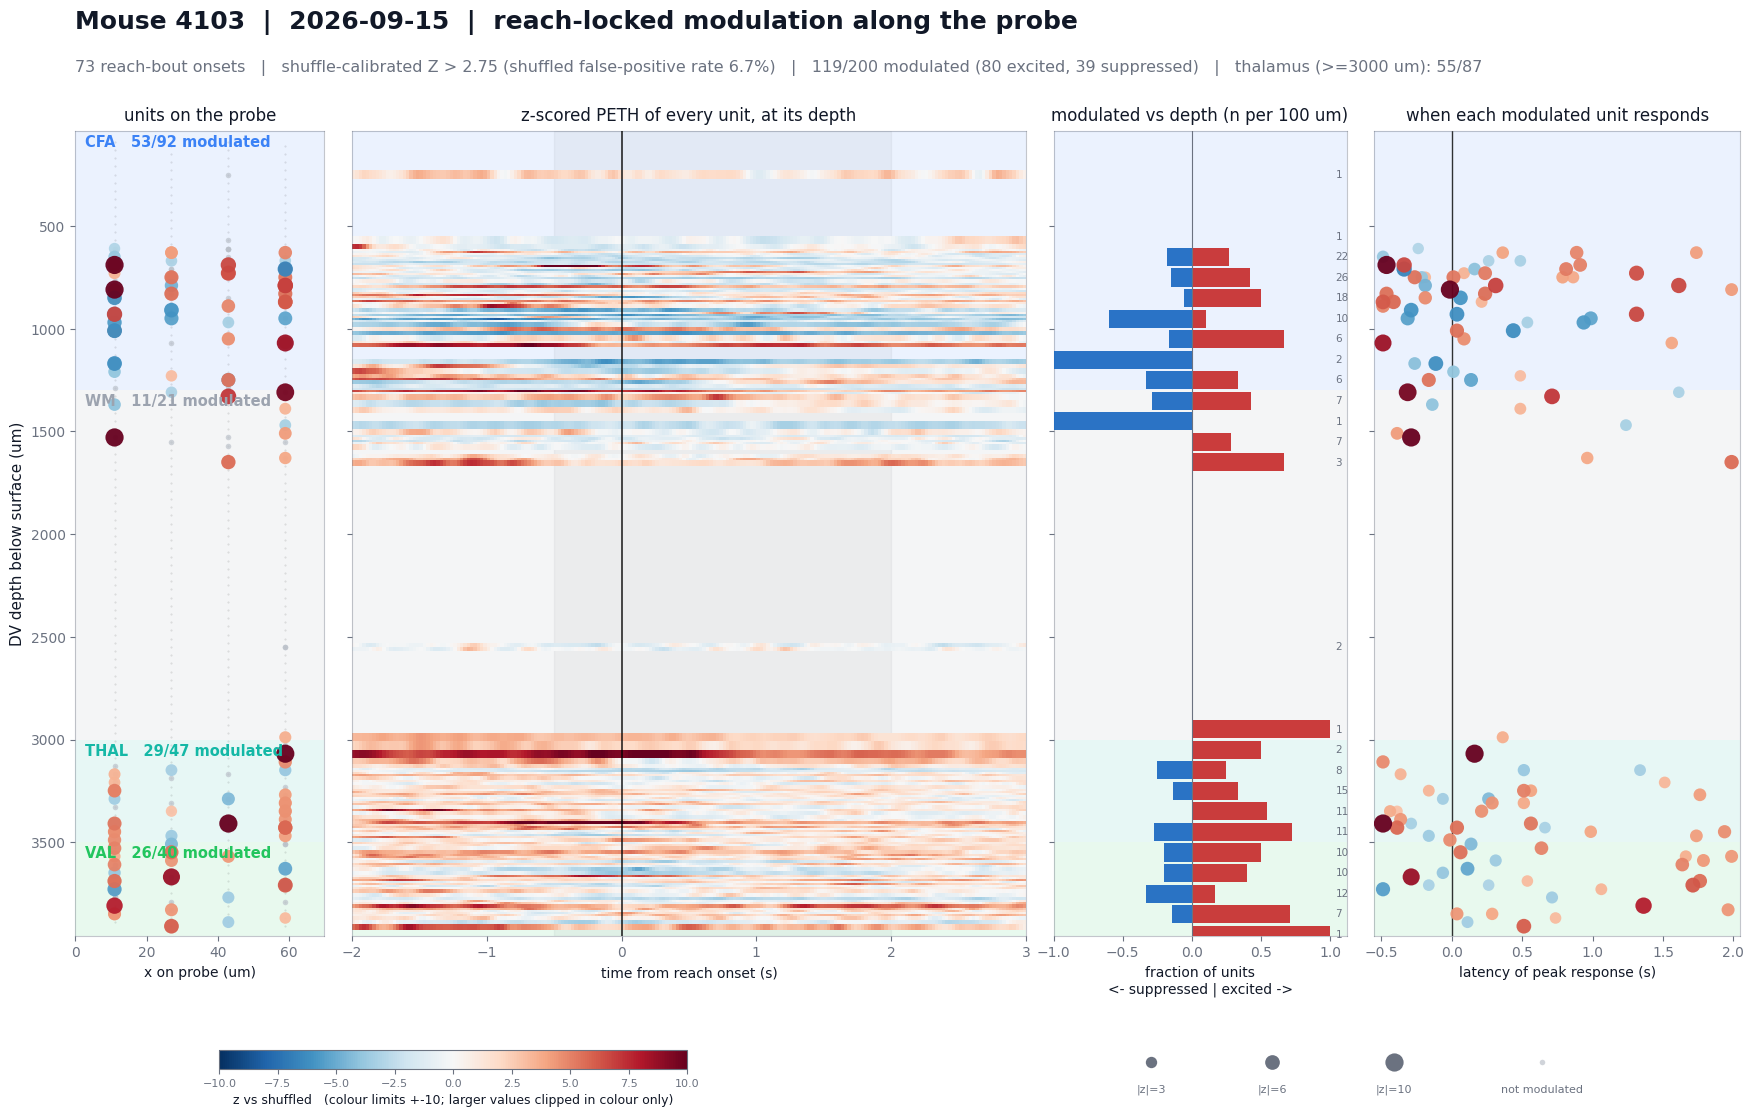

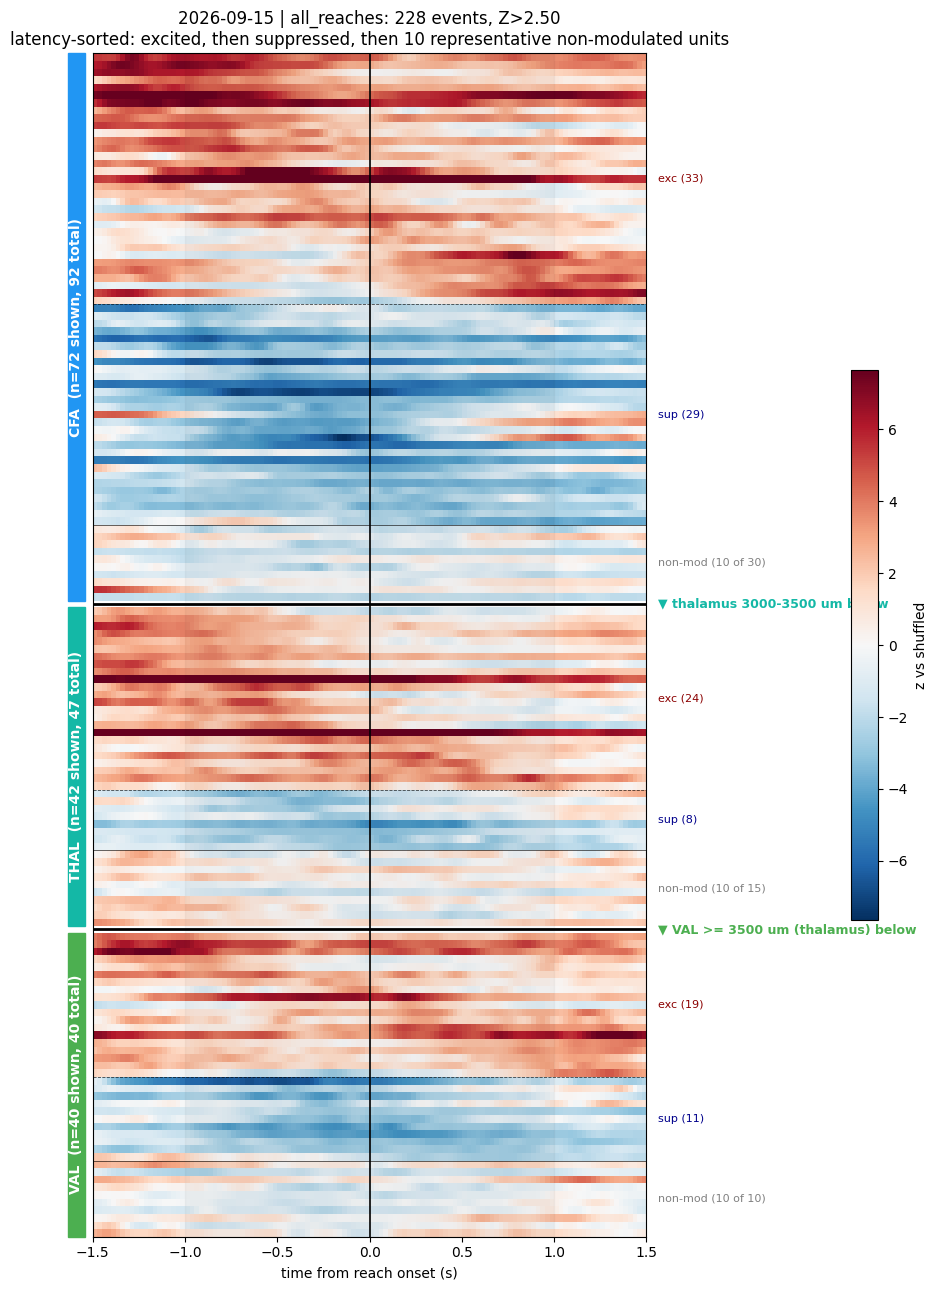

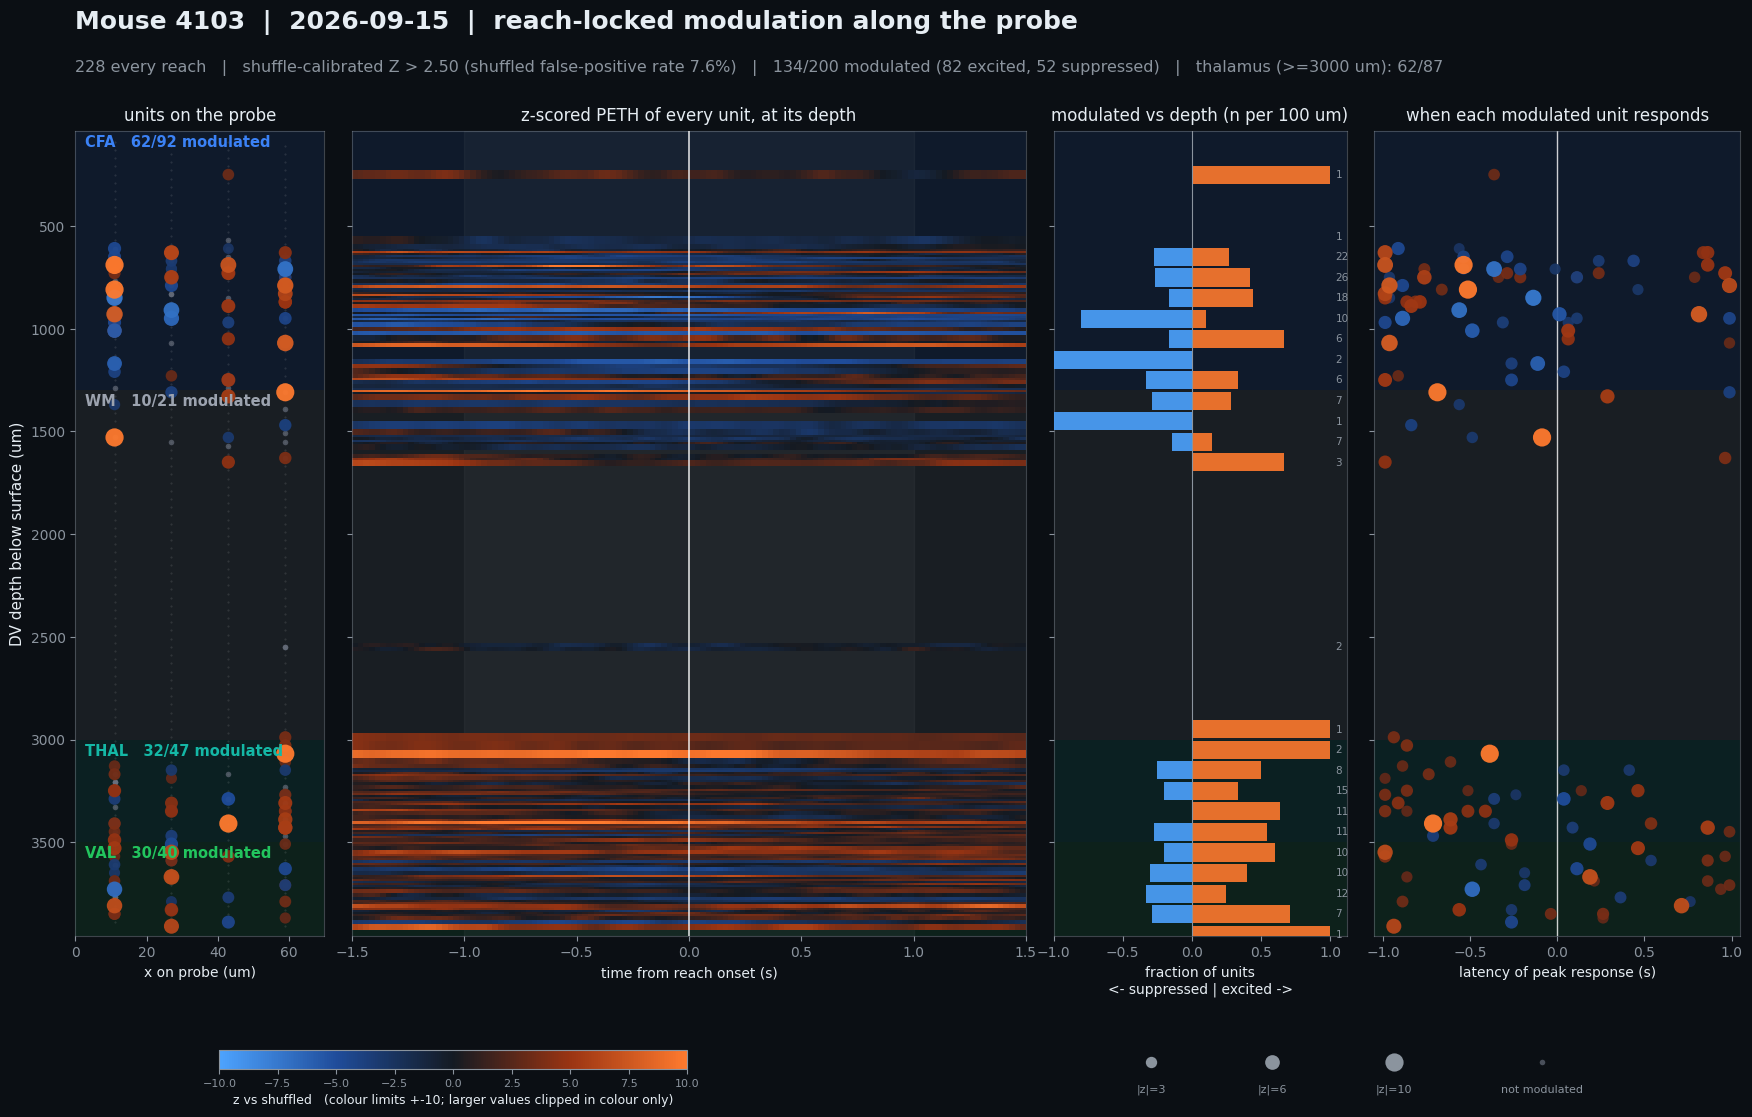

all (73 events, Z>2.75) vs all_reaches (228 events, Z>2.50) on 200 units:
  modulated in both 108, only all 11, only all_reaches 26, neither 55;  same direction in 108/108 of the shared ones;  peak-z correlation r=0.94


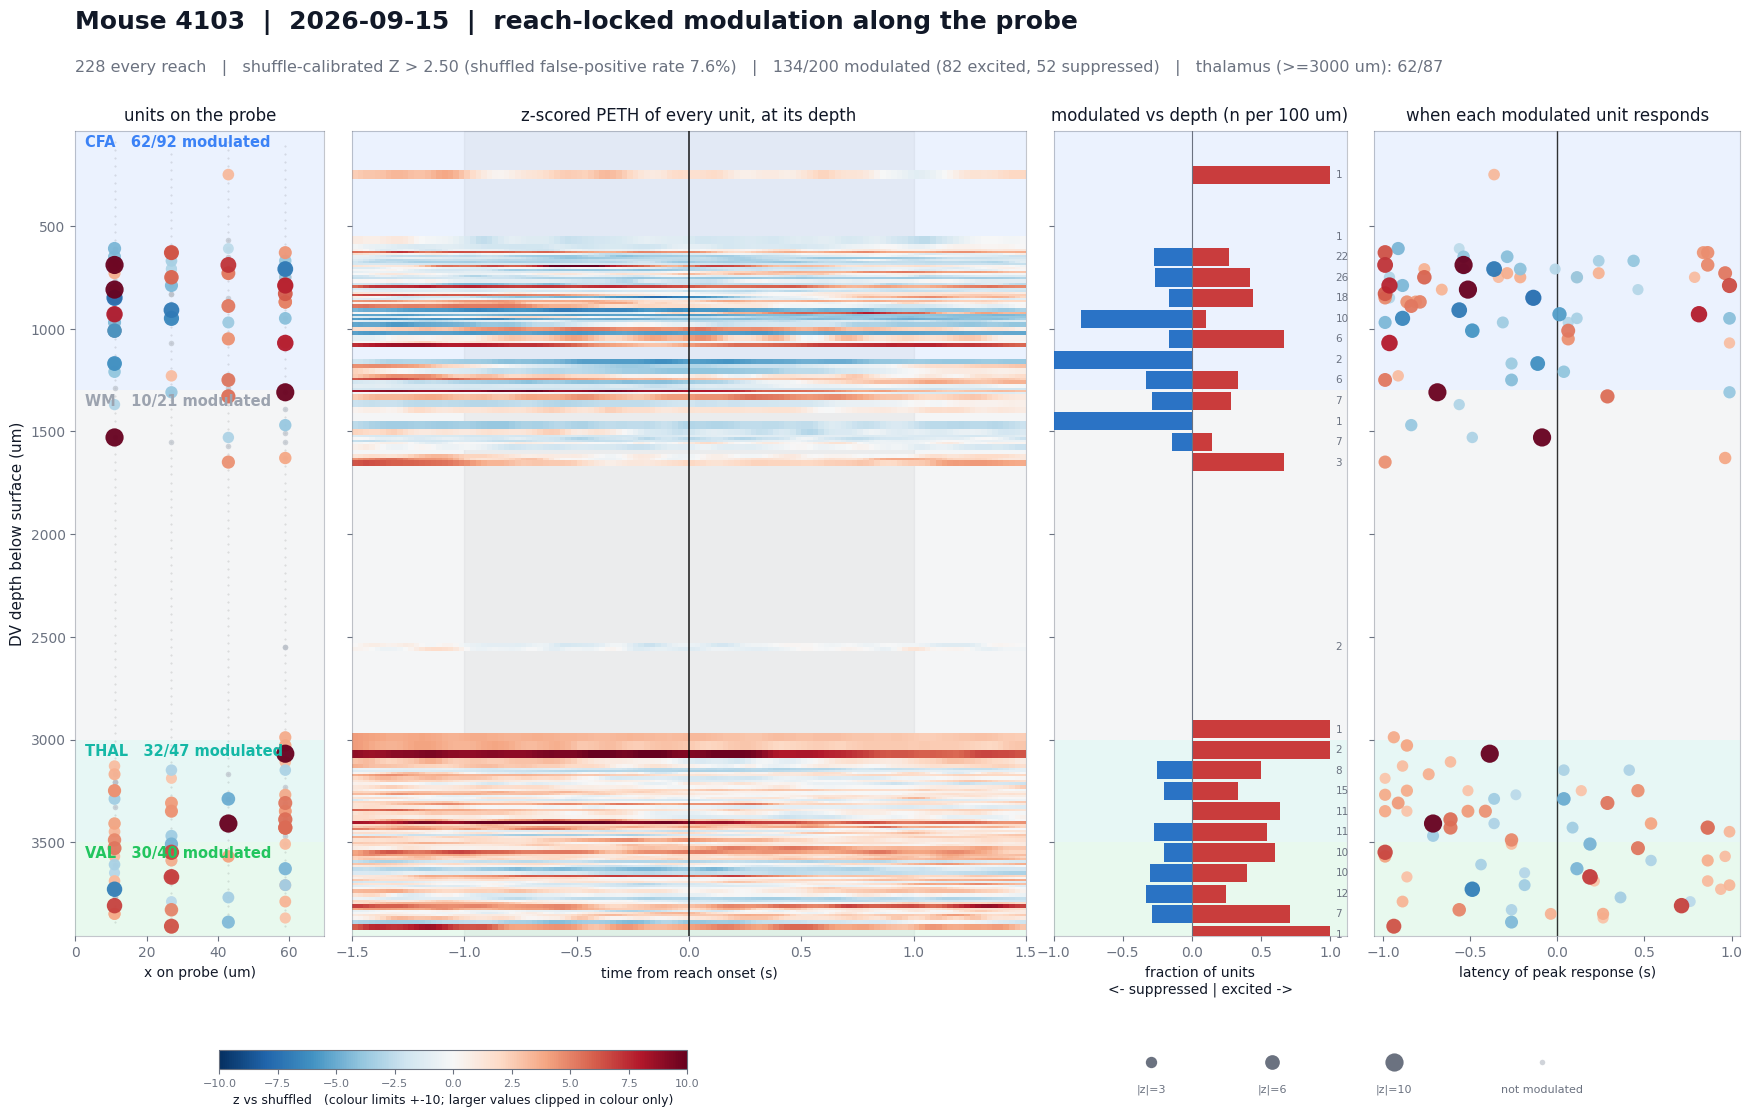

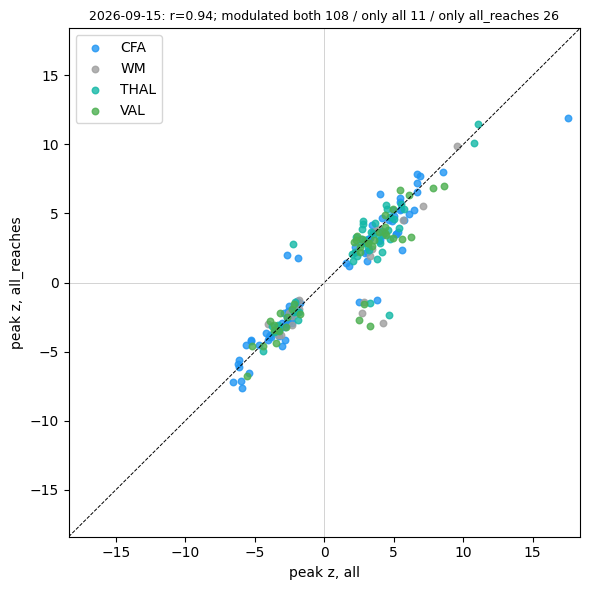

In [3]:
# --- stages 0-3 ----------------------------------------------------------------
run_layout(cfg)
run_sync(cfg)
run_frames(cfg)
units = run_units(cfg)
plot_probe_units(cfg, units); plt.show()
run_dlc(cfg)

# --- stage 5: reaches ----------------------------------------------------------
if cfg.reach_zone:
    detect_reaches(cfg)
    plot_reach_zone(cfg); plt.show()

    # --- stage 6: reach-locked PETH (shuffle-calibrated), by region and by depth ---------
    res = run_reach_peth(cfg, subset="all")      # or "first_in_trial" / "in_trial"
    plot_reach_peth(cfg, res); plt.show()
    plot_peth_depth(cfg, res); plt.show()
    plot_stacked_regions(cfg, res, "all"); plt.show()   # CFA on top, VAL below, latency-sorted
    plot_probe_modulation(cfg, res, "all", theme="dark"); plt.show()      # responses along the probe
    plot_probe_modulation(cfg, res, "all", theme="light")

    # --- robustness: EVERY reach (not only the first of a bout), window -1.5..+1.5 s, response -1..+1 s.
    # The null keeps each bout's internal reach timing and randomises only where bouts fall.
    res_all = run_reach_peth(cfg, subset="all_reaches")
    plot_stacked_regions(cfg, res_all, "all_reaches"); plt.show()
    plot_probe_modulation(cfg, res_all, "all_reaches", theme="dark"); plt.show()
    plot_probe_modulation(cfg, res_all, "all_reaches", theme="light")
    compare_peth(cfg, "all", "all_reaches"); plt.show()

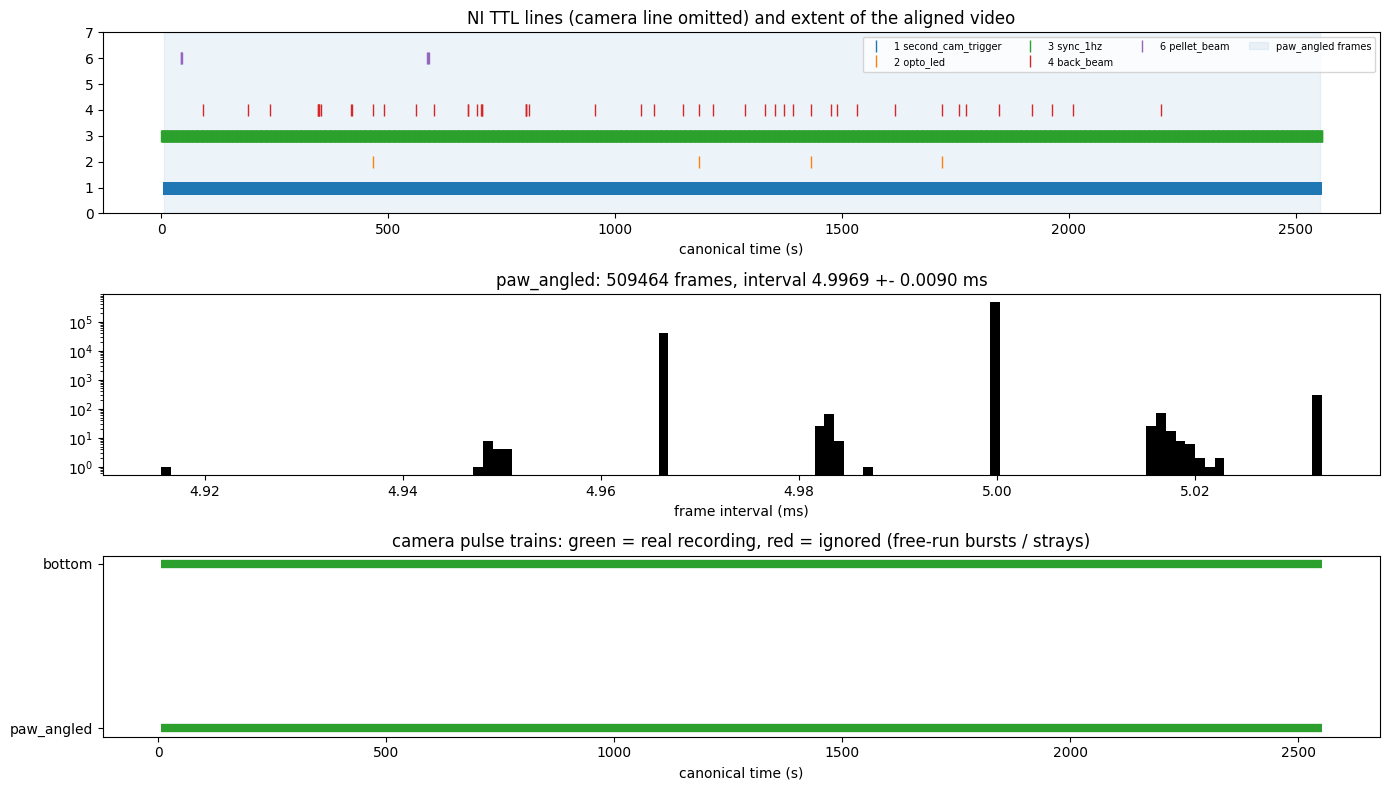

sync residual std: 19.1 us
recording duration: 2557.8 s
paw_angled: video 1, 509464 frames, 0 dropped
bottom: video 1, 306169 frames, 0 dropped


In [4]:
# --- sanity overview -----------------------------------------------------------
tb = read_json(cfg.analysis_dir / "metadata" / "timebase.json")
fa = read_json(cfg.analysis_dir / "metadata" / "frame_alignment.json")
view = cfg.primary_view
ft = load_frame_times(cfg, view)

fig, ax = plt.subplots(3, 1, figsize=(14, 8))
for pin in range(8):
    t = load_ttl(cfg, pin)
    if len(t) and pin != cfg.cameras.get(view, {}).get("pin"):
        ax[0].plot(t, np.full_like(t, pin), "|", ms=8, label=f"{pin} {cfg.pin_labels[pin]}")
ax[0].axvspan(ft[0], ft[-1], color="tab:blue", alpha=0.08, label=f"{view} frames")
ax[0].set_yticks(range(8)); ax[0].set_xlabel("canonical time (s)")
ax[0].set_title("NI TTL lines (camera line omitted) and extent of the aligned video")
ax[0].legend(fontsize=7, ncol=4, loc="upper right")

iv = np.diff(ft) * 1e3
ax[1].hist(iv, bins=np.linspace(iv.min(), min(iv.max(), 10), 120), color="k")
ax[1].set_yscale("log"); ax[1].set_xlabel("frame interval (ms)")
ax[1].set_title(f"{view}: {len(ft)} frames, interval {iv.mean():.4f} +- {iv.std():.4f} ms")

for v, r in fa.items():
    for i, tr in enumerate(r["trains"]):
        ax[2].plot([tr["t_start"], tr["t_end"]], [list(fa).index(v)] * 2, lw=6,
                   color="tab:green" if tr["triggered"] else "tab:red", solid_capstyle="butt")
ax[2].set_yticks(range(len(fa))); ax[2].set_yticklabels(list(fa))
ax[2].set_xlabel("canonical time (s)")
ax[2].set_title("camera pulse trains: green = real recording, red = ignored (free-run bursts / strays)")
plt.tight_layout(); plt.show()

print("sync residual std: %.1f us" % (tb["sync"]["resid_std_s"] * 1e6))
print("recording duration: %.1f s" % tb["recording_duration_s"])
for v, r in fa.items():
    print(f"{v}: video {r['video']}, {r['n_saved']} frames, {r['n_dropped']} dropped")